<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [PySAL Spatial Analysis](https://github.com/Query-farm/vgi-pysal)

Spatial weights, autocorrelation tests, map classification, inequality measures, and spatial regression from PySAL, callable from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-pysal/blob/main/notebooks/04_a_saved_model_has_a_lifecycle.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-pysal/blob/main/notebooks/README.md)

## A saved model preserves coefficients, not a new outcome

Can a model retrieved by name reproduce its coefficient equation, and what changes when only one scoring feature changes? Fit an OLS model to the **same 25 invented sensor readings** used in the first notebook. Inspect its registry entry, reconstruct predictions in SQL, then scale one scoring feature without refitting.

The exercise demonstrates model storage and calculation. Training residuals are not held-out accuracy; the changed-feature scenario has no observed outcomes. All model writes are confined to a new temporary directory that is removed at cleanup.

### Choose one change

Edit the parameter below, then restart and run all. The saved default and the final experiment use the same source rows.

In [1]:
SCORING_SCALE = 1.0  # Experiment: 1.5

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("pysal")
import hashlib
import json
import os
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

theme()
session = connect(globals())
con = session.connection
previous = {name: os.environ.get(name) for name in ["MPLBACKEND", "PYSAL_MODELS_DIR"]}
model_directory = TemporaryDirectory(prefix="pysal-example-models-")
os.environ.update(MPLBACKEND="Agg", PYSAL_MODELS_DIR=model_directory.name)

assert type(SCORING_SCALE) in (int, float) and np.isfinite(SCORING_SCALE) and 0.5 <= SCORING_SCALE <= 1.5
chart_source = "Invented 25-sensor readings · released PySAL v0.1.0 · OLS, fixed training rows\nScenario changes scoring features only; no held-out outcomes, forecasts or causal effects."

### Connect the published worker

The short Git-tag command runs the released worker in an isolated environment. Shared setup retrieves verified example files. Computation uses bundled or explicitly invented data; no external account is needed. The model registry is isolated in a temporary directory and removed at cleanup.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pysal' (
  TYPE vgi,
  LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-pysal@v0.1.0 vgi-pysal'
);

,Success


### Separate coordinates, keys, target and features

The worker treats numeric columns other than the target, ID and coordinate columns as explanatory variables. Name the predictors explicitly as `feature_x` and `feature_y`, while preserving `x` and `y` as coordinates. This prevents an ID from accidentally becoming a predictor. OLS here estimates an intercept and two slopes; the first notebook handles spatial autocorrelation separately.

In [5]:
%%sql
CREATE TABLE sensors AS SELECT * FROM read_csv_auto('fixtures/sensors.csv');
CREATE TABLE training AS SELECT sensor_id,x,y,reading AS target,x AS feature_x,y AS feature_y FROM sensors ORDER BY sensor_id;
CREATE TABLE scoring AS SELECT sensor_id,feature_x,feature_y,feature_x*{{SCORING_SCALE}} AS scenario_x FROM training;
CREATE TABLE coefficients AS SELECT * FROM pysal.main.spreg((SELECT * FROM training ORDER BY sensor_id),model:='ols',target:='target',id:='sensor_id',w_type:='knn',k:=3);
CREATE TABLE fitted AS SELECT * FROM pysal.main.fit((SELECT * FROM training ORDER BY sensor_id),model:='ols',target:='target',id:='sensor_id',w_type:='knn',k:=3,model_name:='notebook_ols');

,Count


In [6]:
%%sql coefficients <<
SELECT variable,coefficient,is_spatial FROM coefficients ORDER BY variable;

In [7]:
display(coefficients)
fit_summary = con.execute("SELECT * EXCLUDE(model) FROM fitted").df()
display(fit_summary)
fixture_hash = hashlib.sha256(Path("fixtures/sensors.csv").read_bytes()).hexdigest()
assert fixture_hash == json.loads(Path("fixtures/provenance.json").read_text())["sha256"]
prose(
    f"The model fits **{int(fit_summary.n.iloc[0])} authored rows** with **{int(fit_summary.k.iloc[0])} parameters** including the intercept. Its stored feature order is explicit. The coefficient table and saved fit use identical ordered training data; neither reports an out-of-sample result."
)

,variable,coefficient,is_spatial
0,CONSTANT,10.173439,False
1,feature_x,1.999112,False
2,feature_y,1.497535,False


,model_name,model_type,target,n,k,r2,pseudo_r2,log_likelihood,aic,spatial_coef,features
0,notebook_ols,ols,target,25,3,0.896155,NaN,-40.162784,86.325568,NaN,"[feature_x, feature_y]"


The model fits **25 authored rows** with **3 parameters** including the intercept. Its stored feature order is explicit. The coefficient table and saved fit use identical ordered training data; neither reports an out-of-sample result.

### Inspect the persisted model before scoring

`fit` writes one named model into this session’s isolated registry. List the entries, then retrieve that exact name. The metadata records estimator, target, feature order and training count; it does not establish compatibility with arbitrary future data. The model is a JSON-backed linear predictor, not a live link to training rows.

In [8]:
%%sql
CREATE TABLE registry_entries AS SELECT * FROM pysal.main.list_models();
CREATE TABLE selected_model AS SELECT * FROM pysal.main.model_info('notebook_ols');

,Count


In [9]:
%%sql registry <<
SELECT model_name,model_type,target,n,k,features,created_at FROM registry_entries;

In [10]:
display(registry)
details = con.execute("SELECT model_name,model_type,n,k,features FROM selected_model").df()
display(details)
assert len(registry) == len(details) == 1 and registry.model_name.iloc[0] == "notebook_ols"
assert details.model_type.iloc[0] == "ols" and int(details.n.iloc[0]) == 25
prose(
    "The isolated registry contains exactly **notebook_ols**; lookup confirms the same OLS estimator, 25-row training scope and two named explanatory features. Scoring below uses this verified name."
)

,model_name,model_type,target,n,k,features,created_at
0,notebook_ols,ols,target,25,3,"[feature_x, feature_y]",2026-11-15T01:46:22.714896+00:00


,model_name,model_type,n,k,features
0,notebook_ols,ols,25,3,"[feature_x, feature_y]"


The isolated registry contains exactly **notebook_ols**; lookup confirms the same OLS estimator, 25-row training scope and two named explanatory features. Scoring below uses this verified name.

### Reconstruct the equation and change one feature

Predict once at the original features and once with `feature_x × SCORING_SCALE`; keep IDs and `feature_y` unchanged. SQL independently reconstructs the intercept-plus-slopes equation from `spreg`. The predicted change should equal `slope_x × (scenario_x − original_x)` for every row. No model refit occurs in this comparison.

For spatial lag/error estimators the worker’s prediction is the systematic component; it does not replay spatial feedback on a new graph. This example deliberately uses OLS so its full fitted value is the linear equation shown.

In [11]:
%%sql
CREATE TABLE baseline_predictions AS SELECT * FROM pysal.main.predict((SELECT sensor_id,feature_x,feature_y FROM scoring ORDER BY sensor_id),model_name:='notebook_ols',id:='sensor_id');
CREATE TABLE scenario_predictions AS SELECT * FROM pysal.main.predict((SELECT sensor_id,scenario_x AS feature_x,feature_y FROM scoring ORDER BY sensor_id),model_name:='notebook_ols',id:='sensor_id');
CREATE TABLE equation AS SELECT max(coefficient) FILTER(WHERE variable='CONSTANT') AS intercept,max(coefficient) FILTER(WHERE variable='feature_x') AS slope_x,max(coefficient) FILTER(WHERE variable='feature_y') AS slope_y FROM coefficients;
CREATE TABLE prediction_audit AS SELECT t.sensor_id,t.target,s.feature_x,s.feature_y,s.scenario_x,b.prediction AS baseline_prediction,p.prediction AS scenario_prediction,
e.intercept+e.slope_x*s.feature_x+e.slope_y*s.feature_y AS reconstructed_baseline,
e.intercept+e.slope_x*s.scenario_x+e.slope_y*s.feature_y AS reconstructed_scenario,
e.slope_x*(s.scenario_x-s.feature_x) AS expected_change
FROM training t JOIN scoring s USING(sensor_id) JOIN baseline_predictions b USING(sensor_id) JOIN scenario_predictions p USING(sensor_id) CROSS JOIN equation e;

,Count


In [12]:
%%sql predictions <<
SELECT * FROM prediction_audit ORDER BY sensor_id;

In [13]:
display(predictions)
rmse = float(np.sqrt(np.mean((predictions.baseline_prediction - predictions.target) ** 2)))
outside = int(
    (
        (predictions.scenario_x < predictions.feature_x.min())
        | (predictions.scenario_x > predictions.feature_x.max())
    ).sum()
)
prose(
    f"Original-feature training RMSE is **{rmse:.4f} arbitrary reading units**. With x-feature scale **{SCORING_SCALE:g}**, **{outside}/25 scoring rows** lie outside the training x-feature range. Their returned values are scenario calculations with no new observed targets; the training RMSE does not validate them."
)

,sensor_id,target,feature_x,feature_y,scenario_x,baseline_prediction,scenario_prediction,reconstructed_baseline,reconstructed_scenario,expected_change
0,S00,10.080000,0.040000,0.000000,0.040000,10.253403,10.253403,10.253403,10.253403,0.0
1,S01,13.372695,1.006238,0.047370,1.006238,12.255959,12.255959,12.255959,12.255959,0.0
2,S02,13.678907,1.961945,0.058147,1.961945,14.182664,14.182664,14.182664,14.182664,0.0
3,S03,14.796235,2.981894,0.024004,2.981894,16.170526,16.170526,16.170526,16.170526,0.0
4,S04,18.664138,4.032407,-0.028682,4.032407,18.191719,18.191719,18.191719,18.191719,0.0
5,S05,12.505645,0.028214,0.940789,0.028214,11.638706,11.638706,11.638706,11.638706,0.0
6,S06,12.476948,0.976392,0.956001,0.976392,13.557001,13.557001,13.557001,13.557001,0.0
7,S07,14.633071,1.964423,1.005202,1.964423,15.605866,15.605866,15.605866,15.605866,0.0
8,S08,18.717512,3.012512,1.050385,3.012512,17.768776,17.768776,17.768776,17.768776,0.0
9,S09,20.179688,4.039479,1.056645,4.039479,19.831173,19.831173,19.831173,19.831173,0.0


Original-feature training RMSE is **1.2063 arbitrary reading units**. With x-feature scale **1**, **0/25 scoring rows** lie outside the training x-feature range. Their returned values are scenario calculations with no new observed targets; the training RMSE does not validate them.

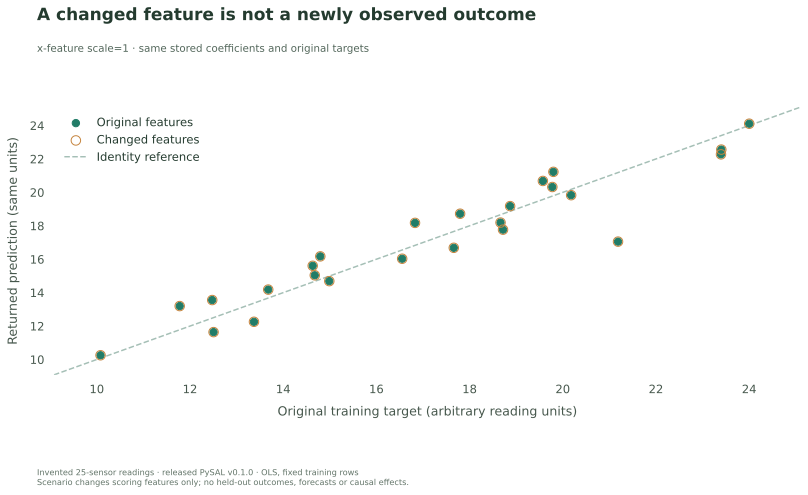

In [14]:
fig, ax = plt.subplots(figsize=(11.8, 7.3))
ax.scatter(
    predictions.target,
    predictions.baseline_prediction,
    s=55,
    color="#217C67",
    label="Original features",
    zorder=3,
)
ax.scatter(
    predictions.target,
    predictions.scenario_prediction,
    s=90,
    facecolors="none",
    edgecolors="#C5843E",
    label="Changed features",
    zorder=4,
)
low = (
    min(
        predictions.target.min(), predictions.baseline_prediction.min(), predictions.scenario_prediction.min()
    )
    - 1
)
high = (
    max(
        predictions.target.max(), predictions.baseline_prediction.max(), predictions.scenario_prediction.max()
    )
    + 1
)
ax.plot([low, high], [low, high], linestyle="--", color="#A5BFB6", label="Identity reference")
ax.set(
    xlabel="Original training target (arbitrary reading units)",
    ylabel="Returned prediction (same units)",
    xlim=(low, high),
    ylim=(low, high),
)
ax.legend(loc="upper left", frameon=False)
finish(
    fig,
    "A changed feature is not a newly observed outcome",
    f"x-feature scale={SCORING_SCALE:g} · same stored coefficients and original targets",
    chart_source,
    name=f"prediction-fit-{SCORING_SCALE:g}",
)

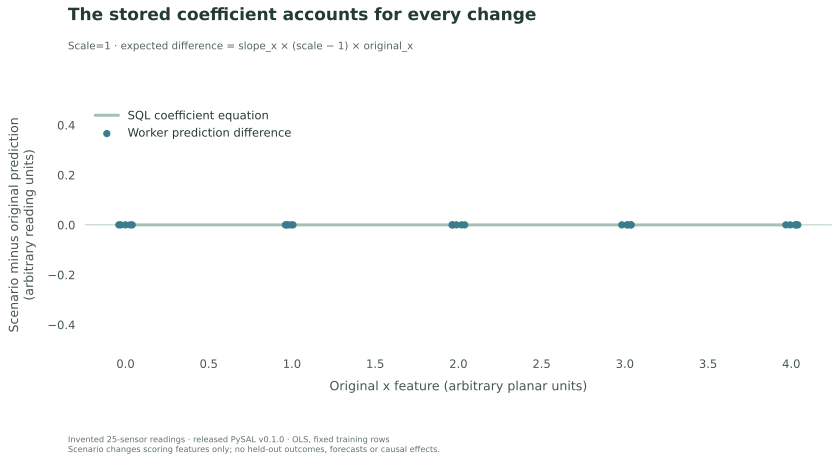

In [15]:
plot = predictions.sort_values("feature_x")
fig, ax = plt.subplots(figsize=(11.8, 6.8))
ax.plot(plot.feature_x, plot.expected_change, color="#A5BFB6", linewidth=3, label="SQL coefficient equation")
ax.scatter(
    plot.feature_x,
    plot.scenario_prediction - plot.baseline_prediction,
    color="#397D8C",
    s=40,
    label="Worker prediction difference",
    zorder=3,
)
ax.axhline(0, color="#A5BFB6", linewidth=0.8)
limit = max(float(abs(plot.expected_change).max()) * 1.15, 0.5)
ax.set(
    xlabel="Original x feature (arbitrary planar units)",
    ylabel="Scenario minus original prediction\n(arbitrary reading units)",
    ylim=(-limit, limit),
)
ax.legend(loc="upper left", frameon=False)
finish(
    fig,
    "The stored coefficient accounts for every change",
    f"Scale={SCORING_SCALE:g} · expected difference = slope_x × (scale − 1) × original_x",
    chart_source,
    name=f"prediction-change-{SCORING_SCALE:g}",
)

### Check the model contract, then delete only this example

Verify row identity, feature preservation and both equations before deleting the named model. A successful deletion and subsequent absent lookup demonstrate the registry lifecycle. This affects only the temporary directory created for this notebook.

In [16]:
%%sql checks <<
SELECT 'Training keys unique' AS check_name,count(*)=25 AND count(DISTINCT sensor_id)=25 AS passed FROM training
UNION ALL SELECT 'Exactly three OLS coefficients',count(*)=3 AND count(DISTINCT variable)=3 AND bool_and(NOT is_spatial) FROM coefficients
UNION ALL SELECT 'Prediction roster complete',count(*)=25 AND count(DISTINCT sensor_id)=25 FROM prediction_audit
UNION ALL SELECT 'Predictions finite',bool_and(isfinite(baseline_prediction) AND isfinite(scenario_prediction)) FROM prediction_audit
UNION ALL SELECT 'Baseline equation matches',bool_and(abs(baseline_prediction-reconstructed_baseline)<1e-9) FROM prediction_audit
UNION ALL SELECT 'Scenario equation matches',bool_and(abs(scenario_prediction-reconstructed_scenario)<1e-9) FROM prediction_audit
UNION ALL SELECT 'Change equals coefficient effect',bool_and(abs(scenario_prediction-baseline_prediction-expected_change)<1e-9) FROM prediction_audit
UNION ALL SELECT 'Training metadata matches',n=25 AND k=3 AND model_type='ols' AND spatial_coef IS NULL FROM fitted;

In [17]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(
    f"All **{len(checks)} SQL checks** pass. Every returned change is accounted for by the fixed coefficient equation; that is a numerical contract, not a causal claim."
)

,check_name,passed
0,Training keys unique,True
1,Exactly three OLS coefficients,True
2,Prediction roster complete,True
3,Predictions finite,True
4,Baseline equation matches,True
5,Scenario equation matches,True
6,Change equals coefficient effect,True
7,Training metadata matches,True


All **8 SQL checks** pass. Every returned change is accounted for by the fixed coefficient equation; that is a numerical contract, not a causal claim.

In [18]:
%%sql
CREATE TABLE deletion AS SELECT * FROM pysal.main.drop_model('notebook_ols');
CREATE TABLE after_delete AS SELECT * FROM pysal.main.model_info('notebook_ols');
CREATE TABLE after_registry AS SELECT * FROM pysal.main.list_models();

,Count


In [19]:
dropped = con.execute("SELECT * FROM deletion").df()
display(dropped)
assert len(dropped) == 1 and bool(dropped.dropped.iloc[0])
assert con.execute("SELECT count(*) FROM after_delete").fetchone()[0] == 0
assert con.execute("SELECT count(*) FROM after_registry").fetchone()[0] == 0
prose(
    "Deletion returned **True**; both name lookup and registry listing are now empty. The predictions already materialized in SQL remain available as results of the earlier computation."
)

,model_name,dropped
0,notebook_ols,True


Deletion returned **True**; both name lookup and registry listing are now empty. The predictions already materialized in SQL remain available as results of the earlier computation.

### Experiment: scale the scoring x feature

Change only `SCORING_SCALE=1.0` to **1.5**. The training fixture, fitted coefficients, registry metadata scope and original-feature RMSE must remain unchanged. Predict the sign and relative size of changes from the x coefficient, then compare the returned differences. Re-running recreates and later removes an isolated registry; no existing models are used or deleted.

In [20]:
session.close()
model_directory.cleanup()
for name, value in previous.items():
    if value is None:
        os.environ.pop(name, None)
    else:
        os.environ[name] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-pysal](https://github.com/Query-farm/vgi-pysal)